# Thesis plotting style

Two pieces live in the `qcg-quantum-design` package (installed into both the
`quantum` and `qcg-quantum-design` conda envs):

- **`thesis_cmaps`** — the colormaps (sections 1–7).
- **`thesis_style`** — the categorical colour cycle, a standalone rcParams
  style, and plotting helpers (sections 8–13).

Everything is built from one palette:
`#03AED2` blue · `#F8DE22` yellow · `#F45B26` orange · `#D12052` red.

| registered name | kind | notes |
|------|------|-------|
| `thesis_cmap` (`_r`)           | sequential | blue → yellow → orange → red, ends pushed to `#02566A` / `#9E0E3E` |
| `thesis_cmap_diverging` (`_r`) | diverging  | blue (−) → white (0) → red (+) |
| `thesis_cat`                   | categorical (`ListedColormap`) | the 6 cycle colours |

(`qcg` / `qcg_r` stay registered as legacy aliases of `thesis_cmap`.)

registered : {'thesis_cmap': True, 'thesis_cmap_r': True, 'thesis_cmap_diverging': True, 'thesis_cmap_diverging_r': True}
palette    : ['#03AED2', '#F8DE22', '#F45B26', '#D12052']


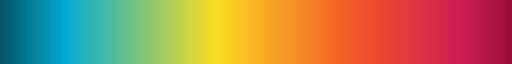

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
plt.style.use(['science', 'no-latex', 'notebook'])

import thesis_cmaps   # registers the colormaps

names = ["thesis_cmap", "thesis_cmap_r",
         "thesis_cmap_diverging", "thesis_cmap_diverging_r"]
print("registered :", {n: n in plt.colormaps() for n in names})
print("palette    :", thesis_cmaps.THESIS_PALETTE)
thesis_cmaps.thesis_cmap

## 1. The two colormaps

Forward and reversed ramps, with the control points marked underneath.

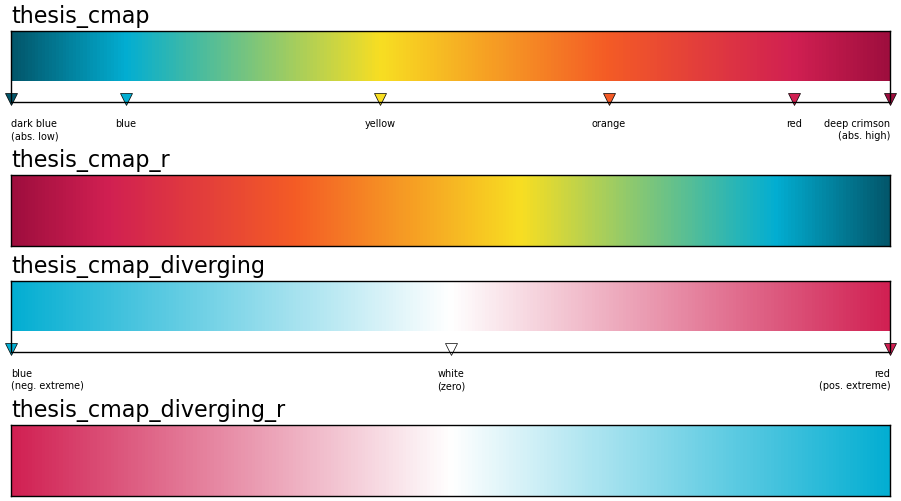

In [2]:
grad = np.linspace(0, 1, 256)[None, :]

seq_pts = [
    (0.00, "#02566A", "dark blue\n(abs. low)"),
    (0.13, "#03AED2", "blue"),
    (0.42, "#F8DE22", "yellow"),
    (0.68, "#F45B26", "orange"),
    (0.89, "#D12052", "red"),
    (1.00, "#9E0E3E", "deep crimson\n(abs. high)"),
]
div_pts = [
    (0.0, "#03AED2", "blue\n(neg. extreme)"),
    (0.5, "#FFFFFF", "white\n(zero)"),
    (1.0, "#D12052", "red\n(pos. extreme)"),
]

fig, axes = plt.subplots(4, 1, figsize=(9, 5), constrained_layout=True)
specs = [("thesis_cmap", seq_pts), ("thesis_cmap_r", None),
         ("thesis_cmap_diverging", div_pts), ("thesis_cmap_diverging_r", None)]
for ax, (name, pts) in zip(axes, specs):
    ax.imshow(grad, aspect="auto", cmap=name, extent=[0, 1, 0, 1])
    ax.set_yticks([]); ax.set_xticks([]); ax.set_title(name, loc="left")
    if pts:
        for pos, col, label in pts:
            ha = "left" if pos == 0 else "right" if pos == 1 else "center"
            ax.plot([pos], [-0.35], marker="v", ms=9, color=col,
                    mec="k", mew=0.5, clip_on=False)
            ax.text(pos, -0.75, label, ha=ha, va="top", fontsize=7)
plt.show()

## 2. Sequential map — a scalar field

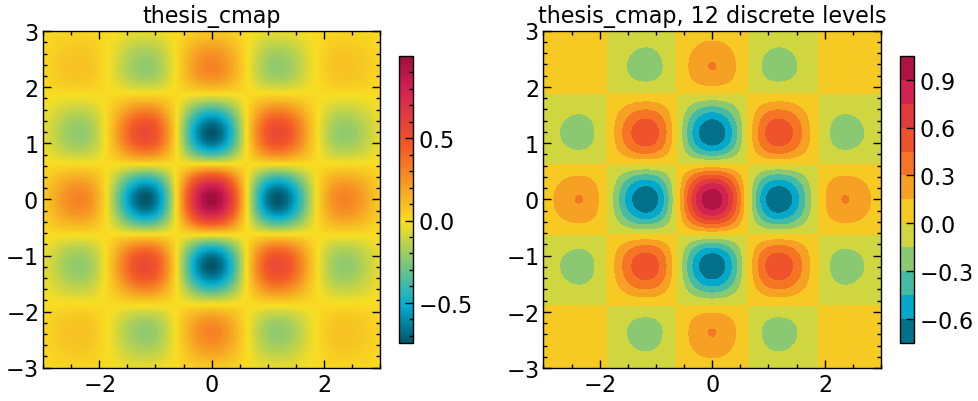

In [3]:
x = np.linspace(-3, 3, 400)
X, Y = np.meshgrid(x, x)
Z = np.cos(2.5 * X) * np.cos(2.5 * Y) * np.exp(-(X**2 + Y**2) / 5)

fig, (a0, a1) = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
im0 = a0.pcolormesh(X, Y, Z, cmap="thesis_cmap", shading="auto")
a0.set_title("thesis_cmap"); a0.set_aspect("equal")
fig.colorbar(im0, ax=a0, shrink=0.85)
im1 = a1.contourf(X, Y, Z, levels=12, cmap="thesis_cmap")
a1.set_title("thesis_cmap, 12 discrete levels"); a1.set_aspect("equal")
fig.colorbar(im1, ax=a1, shrink=0.85)
plt.show()

## 3. Sequential map — a family of ordered curves

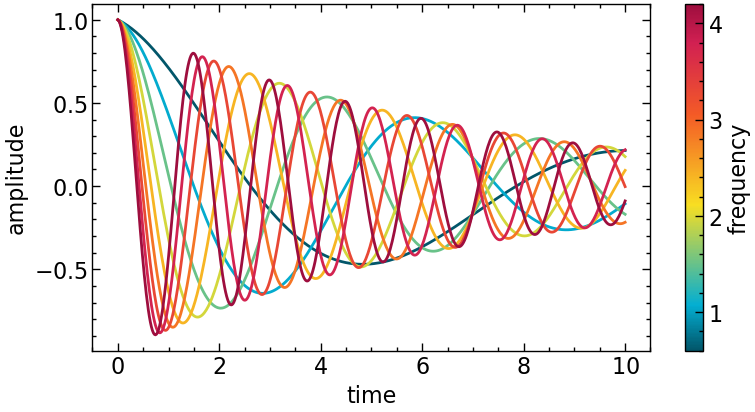

In [4]:
cmap = plt.get_cmap("thesis_cmap")
t = np.linspace(0, 10, 500)
n_curves = 9

fig, ax = plt.subplots(figsize=(9, 4.5))
for i in range(n_curves):
    w = 0.6 + 0.45 * i
    ax.plot(t, np.exp(-0.15 * t) * np.cos(w * t),
            color=cmap(i / (n_curves - 1)), lw=2)
ax.set_xlabel("time"); ax.set_ylabel("amplitude")
sm = plt.cm.ScalarMappable(cmap=cmap,
                           norm=plt.Normalize(0.6, 0.6 + 0.45 * (n_curves - 1)))
fig.colorbar(sm, ax=ax, label="frequency")
plt.show()

## 4. Sequential map — discrete palette

`.resampled(k)` turns the map into `k` evenly spaced bands.

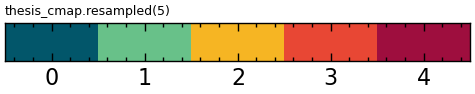

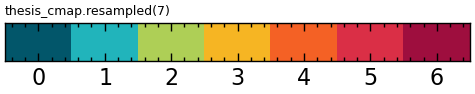

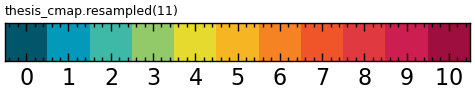

In [5]:
for k in (5, 7, 11):
    disc = plt.get_cmap("thesis_cmap").resampled(k)
    fig, ax = plt.subplots(figsize=(6, 0.5))
    ax.imshow(np.arange(k)[None, :], aspect="auto", cmap=disc)
    ax.set_yticks([]); ax.set_xticks(range(k))
    ax.set_title(f"thesis_cmap.resampled({k})", loc="left", fontsize=9)
    plt.show()

## 5. Diverging map

`thesis_cmap_diverging` is for signed data where zero is meaningful — the sign
of a coupling, a detuning, an error residual. Pair it with a symmetric norm
(`TwoSlopeNorm(vcenter=0)` or `vmin=-a, vmax=+a`) so that white lands exactly
on zero.

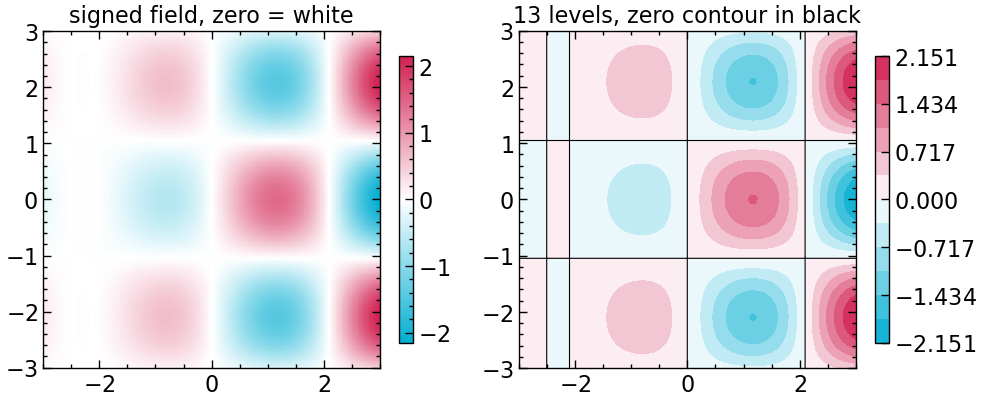

In [6]:
from matplotlib.colors import TwoSlopeNorm

x = np.linspace(-3, 3, 400)
X, Y = np.meshgrid(x, x)
D = np.sin(1.5 * X) * np.cos(1.5 * Y) * (1 + 0.4 * X)   # asymmetric signed field
vmax = np.abs(D).max()

fig, (a0, a1) = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
im0 = a0.pcolormesh(X, Y, D, cmap="thesis_cmap_diverging",
                    norm=TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax),
                    shading="auto")
a0.set_title("signed field, zero = white"); a0.set_aspect("equal")
fig.colorbar(im0, ax=a0, shrink=0.85)

lvls = np.linspace(-vmax, vmax, 13)
im1 = a1.contourf(X, Y, D, levels=lvls, cmap="thesis_cmap_diverging")
a1.contour(X, Y, D, levels=[0], colors="k", linewidths=0.8)
a1.set_title("13 levels, zero contour in black"); a1.set_aspect("equal")
fig.colorbar(im1, ax=a1, shrink=0.85)
plt.show()

### 5b. Why not a yellow centre?

The request was to try yellow as the midpoint first. It doesn't hold up: the
negative half then runs blue → **green** → yellow, so mildly-negative and
strongly-negative values are hard to tell apart and the negative side looks
nothing like a mirror of the yellow → red positive side. A white centre keeps
the two halves symmetric and gives a clean "near zero = blank" reading. The
comparison below is why the registered map uses white.

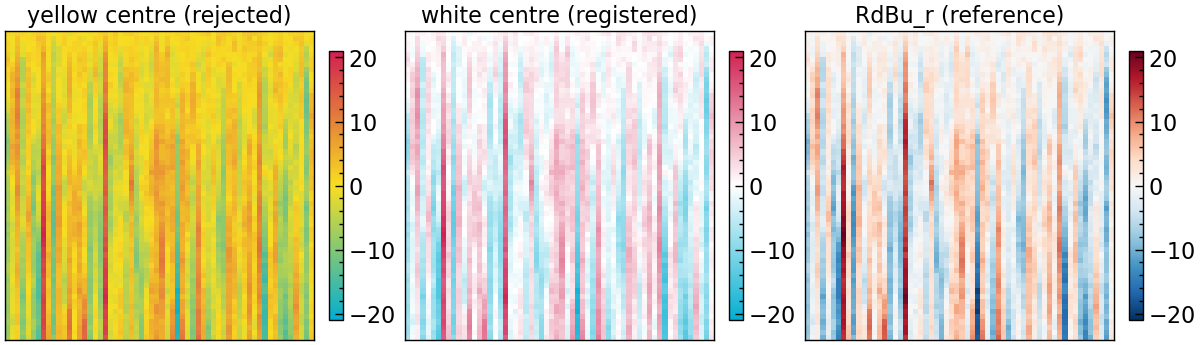

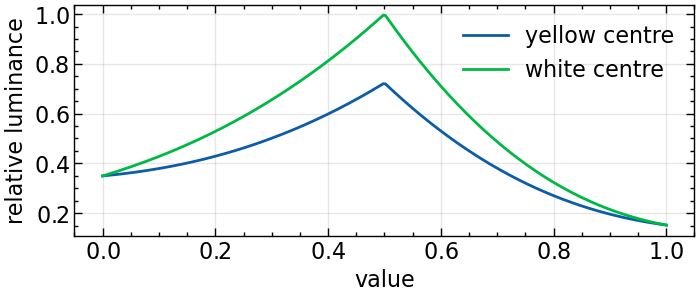

In [7]:
from matplotlib.colors import LinearSegmentedColormap

div_yellow = LinearSegmentedColormap.from_list(
    "thesis_div_yellow",
    [(0.0, "#03AED2"), (0.5, "#F8DE22"), (1.0, "#D12052")], N=256)

rng = np.random.default_rng(0)
G = np.cumsum(rng.normal(size=(60, 60)), axis=0)
G = G - G.mean()
vmax = np.abs(G).max()
norm = TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
for ax, cm, ttl in [(axes[0], div_yellow, "yellow centre (rejected)"),
                    (axes[1], "thesis_cmap_diverging", "white centre (registered)"),
                    (axes[2], "RdBu_r", "RdBu_r (reference)")]:
    im = ax.imshow(G, cmap=cm, norm=norm)
    ax.set_title(ttl); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

# luminance across both diverging options
fig, ax = plt.subplots(figsize=(8, 3))
for cm, lbl in [(div_yellow, "yellow centre"),
                (plt.get_cmap("thesis_cmap_diverging"), "white centre")]:
    cols = cm(np.linspace(0, 1, 256))[:, :3]
    lin = np.where(cols <= 0.04045, cols/12.92, ((cols+0.055)/1.055)**2.4)
    L = lin @ [0.2126, 0.7152, 0.0722]
    ax.plot(np.linspace(0, 1, 256), L, label=lbl)
ax.set_xlabel("value"); ax.set_ylabel("relative luminance")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 6. Thesis-flavoured example: an avoided crossing

Sequential colour tracks the lower-branch content of each eigenstate.

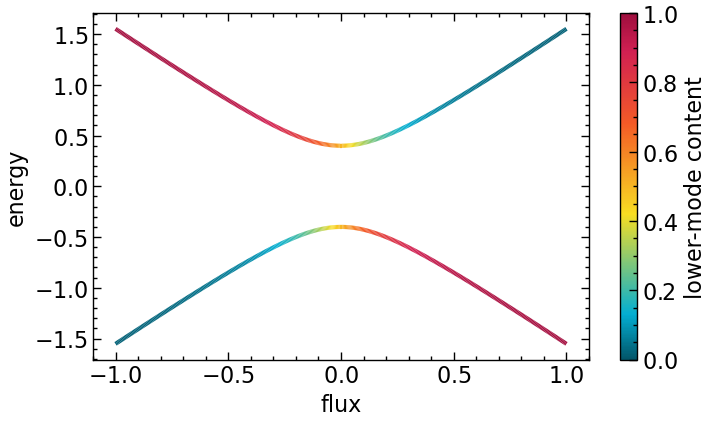

In [8]:
from matplotlib.collections import LineCollection

flux = np.linspace(-1, 1, 400)
delta = 3.0 * flux
g = 0.4
Ep = 0.5 * np.sqrt(delta**2 + 4 * g**2)
Em = -Ep
mix = 0.5 * (1 - delta / np.sqrt(delta**2 + 4 * g**2))

fig, ax = plt.subplots(figsize=(8, 4.5))
for E, m in ((Ep, mix), (Em, 1 - mix)):
    pts = np.column_stack([flux, E]).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    lc = LineCollection(segs, cmap="thesis_cmap", norm=plt.Normalize(0, 1))
    lc.set_array(m); lc.set_linewidth(3)
    ax.add_collection(lc)
ax.autoscale()
ax.set_xlabel("flux"); ax.set_ylabel("energy")
fig.colorbar(plt.cm.ScalarMappable(cmap="thesis_cmap"), ax=ax,
             label="lower-mode content")
plt.show()

## 7. Perceptual check (sequential map)

Built from a bright palette, so its luminance is **not** monotonic — it peaks
around the yellow. Good for qualitative / aesthetic figures; for strictly
quantitative reading where lightness must encode magnitude, prefer a
perceptually uniform map (`viridis`, `magma`).

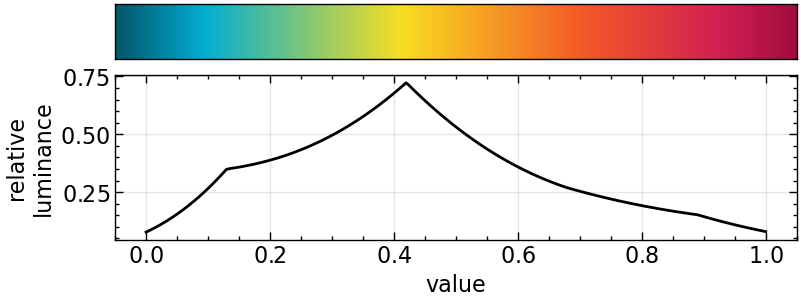

In [9]:
cols = plt.get_cmap("thesis_cmap")(np.linspace(0, 1, 256))[:, :3]
lin = np.where(cols <= 0.04045, cols / 12.92, ((cols + 0.055) / 1.055) ** 2.4)
L = lin @ [0.2126, 0.7152, 0.0722]

fig, (a0, a1) = plt.subplots(2, 1, figsize=(8, 3),
                             gridspec_kw={"height_ratios": [1, 3]},
                             constrained_layout=True)
a0.imshow(np.linspace(0, 1, 256)[None, :], aspect="auto", cmap="thesis_cmap")
a0.set_yticks([]); a0.set_xticks([])
a1.plot(np.linspace(0, 1, 256), L, color="k")
a1.set_xlabel("value"); a1.set_ylabel("relative\nluminance")
a1.grid(alpha=0.3)
plt.show()

---
# `thesis_style` — colour cycle, rcParams, helpers

## 8. The categorical colour cycle

The colormap palette can't be used directly as a line-plot cycle: pure
`#F8DE22` is ~1.3:1 contrast on white (invisible as a thin line), and
`#F45B26`/`#D12052` are only ΔE≈14 apart for normal colour vision. The cycle
fixes both — the yellow is deepened to a **gold** `#E0A500`, two hues are added,
and the order keeps orange and red apart:

`#03AED2` blue → `#F45B26` orange → `#12A594` teal → `#D12052` red →
`#E0A500` gold → `#6A3D9A` purple

It passes the full categorical check (lightness band, chroma floor, CVD
separation, normal-vision floor, contrast).

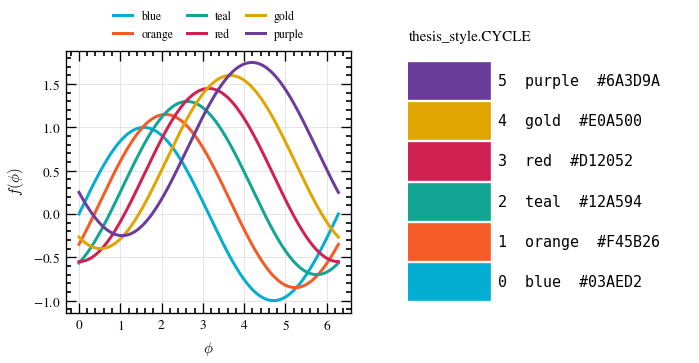

In [10]:
import thesis_style as ts

ts.use()   # apply the standalone style (scienceplots fonts by default)

fig, (a0, a1) = plt.subplots(1, 2, figsize=ts.figsize(2, ratio=0.42))

x = np.linspace(0, 2 * np.pi, 200)
for i in range(6):
    a0.plot(x, np.sin(x - i * np.pi / 6) + 0.15 * i, label=ts.CYCLE_NAMES[i])
a0.set_xlabel(r"$\phi$"); a0.set_ylabel(r"$f(\phi)$")
a0.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=7)

for i, (name, hexv) in enumerate(zip(ts.CYCLE_NAMES, ts.CYCLE)):
    a1.add_patch(plt.Rectangle((0, i), 1, 0.9, color=hexv))
    a1.text(1.1, i + 0.45, f"{i}  {name}  {hexv}", va="center", family="monospace")
a1.set_xlim(0, 3.5); a1.set_ylim(-0.3, 6.2); a1.axis("off")
a1.set_title("thesis_style.CYCLE", loc="left")
ts.finalize(a0)
plt.show()

## 9. Greyscale- / CVD-safe cycle

`ts.use(bw=True)` zips the colours with a linestyle **and** a marker cycle, so
series stay separable in a black-and-white print or for a colour-blind reader.

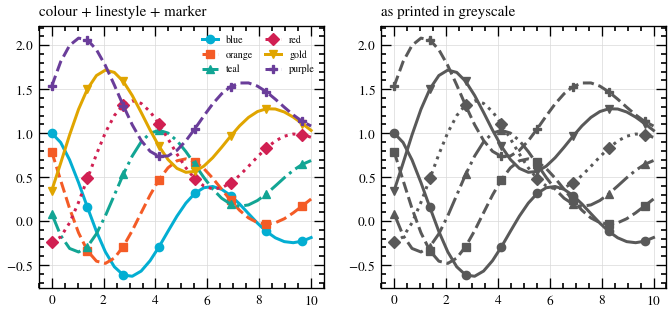

In [11]:
ts.use(bw=True)

fig, (a0, a1) = plt.subplots(1, 2, figsize=ts.figsize(2, ratio=0.42))
x = np.linspace(0, 10, 30)
for i in range(6):
    y = np.exp(-0.15 * x) * np.cos(x + i) + 0.25 * i
    a0.plot(x, y, markevery=4, label=ts.CYCLE_NAMES[i])
    a1.plot(x, y, markevery=4, color="0.35")          # same cycle, colour removed
a0.set_title("colour + linestyle + marker", loc="left")
a1.set_title("as printed in greyscale", loc="left")
a0.legend(ncol=2, fontsize=6)
ts.finalize([a0, a1])
plt.show()

ts.use()   # back to the plain colour cycle

## 10. Categorical colormap

`thesis_cat` (a `ListedColormap`) is the cycle for cases that take a *cmap*
rather than a colour cycle — grouped bars, categorical `imshow`, network nodes.

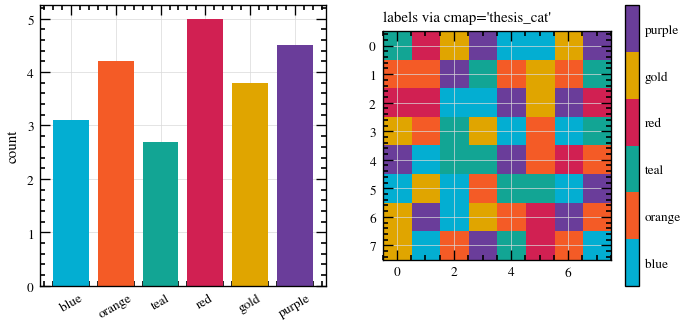

In [12]:
fig, (a0, a1) = plt.subplots(1, 2, figsize=ts.figsize(2, ratio=0.45))

vals = [3.1, 4.2, 2.7, 5.0, 3.8, 4.5]
a0.bar(ts.CYCLE_NAMES, vals, color=ts.CYCLE)
a0.set_ylabel("count"); a0.tick_params(axis="x", rotation=30)

lab = np.random.default_rng(1).integers(0, 6, size=(8, 8))
im = a1.imshow(lab, cmap="thesis_cat", vmin=-0.5, vmax=5.5)
a1.set_title("labels via cmap='thesis_cat'", loc="left")
fig.colorbar(im, ax=a1, ticks=range(6)).set_ticklabels(ts.CYCLE_NAMES)
ts.finalize(a0)
plt.show()

## 11. What `thesis_style.use()` sets

A standalone rcParams style — it does **not** build on scienceplots. Highlights:

| area | setting |
|------|---------|
| colour   | `axes.prop_cycle` = the cycle · `image.cmap` = `thesis_cmap` |
| size     | `figure.figsize` from `ts.figsize(cols, ratio)` · `savefig.dpi` 600 · pdf · tight bbox |
| ticks    | pointing **in**, minor ticks on, top+right spines |
| grid     | light grey, behind the data |
| legend   | frameless |
| numbers  | `axes.formatter.use_mathtext` |
| fonts    | chosen by `typography=` (below) |

`ts.figsize()` gives APS column widths: `ts.figsize(1)` → 3.375 in,
`ts.figsize(2)` → 6.75 in; `ratio` is height/width.

In [13]:
import pprint
pprint.pp({k: plt.rcParams[k] for k in
           ["axes.prop_cycle", "image.cmap", "figure.figsize",
            "xtick.direction", "xtick.minor.visible", "legend.frameon",
            "savefig.dpi", "savefig.bbox"]})

{'axes.prop_cycle': cycler('color', ['#03AED2', '#F45B26', '#12A594', '#D12052', '#E0A500', '#6A3D9A']),
 'image.cmap': 'thesis_cmap',
 'figure.figsize': [3.375, 2.2950000000000004],
 'xtick.direction': 'in',
 'xtick.minor.visible': True,
 'legend.frameon': False,
 'savefig.dpi': 600.0,
 'savefig.bbox': 'tight'}


## 12. Helpers

- `finalize(axs)` — minor ticks on, ticks on all four sides (used throughout above).
- `panel_labels(axs)` — stamp `(a) (b) (c) …`.
- `highlight(ax, i)` — grey every line but the `i`-th, and bring it to the front.
- `save(fig, name)` — write `name.pdf` **and** `name.png` in one call.

save() wrote: ['demo.pdf', 'demo.png']


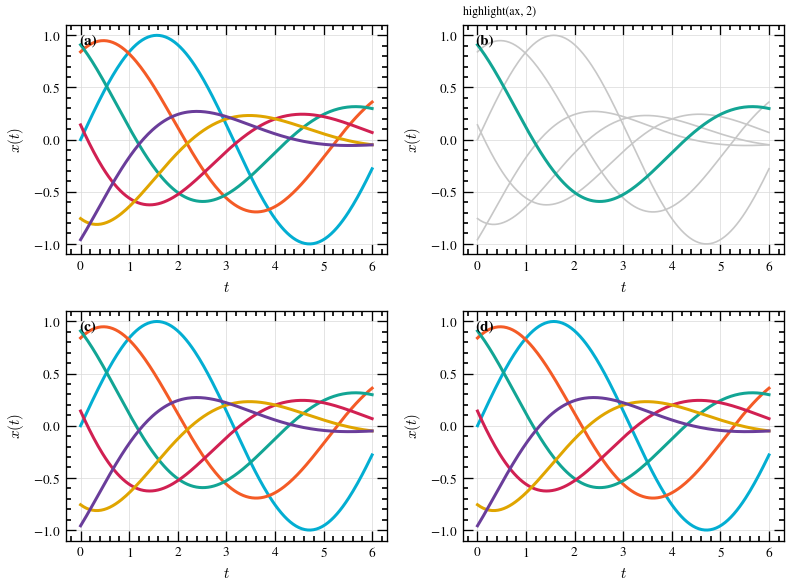

In [14]:
fig, axs = plt.subplots(2, 2, figsize=ts.figsize(2, ratio=0.75))

x = np.linspace(0, 6, 200)
for ax in axs.flat:
    for i in range(6):
        ax.plot(x, np.sin(x + i) * np.exp(-0.1 * i * x))
    ax.set_xlabel(r"$t$"); ax.set_ylabel(r"$x(t)$")

ts.highlight(axs[0, 1], 2)          # spotlight series 2 (teal)
axs[0, 1].set_title("highlight(ax, 2)", loc="left", fontsize=7)

ts.finalize(axs)
ts.panel_labels(axs)
fig.tight_layout()

import tempfile, os
d = tempfile.mkdtemp()
paths = ts.save(fig, "demo", directory=d)
print("save() wrote:", [os.path.basename(p) for p in paths])
plt.show()

## 13. Typography options

`typography=` picks the font. **The default, `'scienceplots'`, reproduces
`plt.style.use(['science', 'no-latex'])`** — STIXGeneral text with
Computer-Modern mathtext, no LaTeX — which is the look this thesis uses. The
other no-LaTeX options are `stix`, `dejavu-serif`, `sans`, `dejavu-sans`; the
LaTeX ones (`newtx` — Times-like maths, `txfonts`, `lmodern`, `palatino`, `cm`;
`cm` == plain `['science']`) need a TeX install. `None` leaves fonts alone.

The comparison below was used to choose; `'scienceplots'` won.

**Each option must be rendered in its own figure.** Matplotlib resolves most
text fonts at *draw* time from the global rcParams, so switching `typography`
between subplots of one figure and drawing them all at the end makes every
panel come out in whichever font was active last — they only differ if each
figure is finished (shown / saved) while its own style is active.

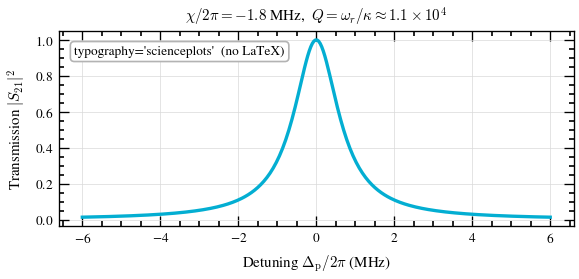

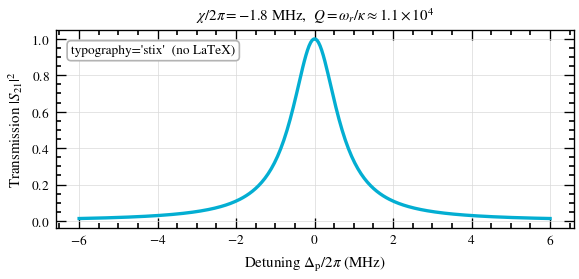

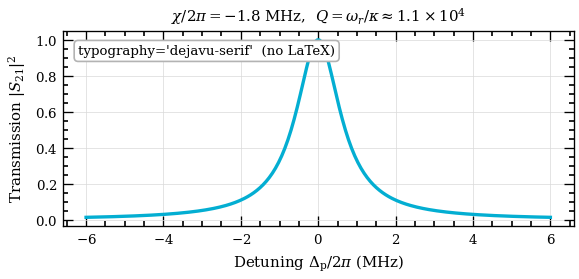

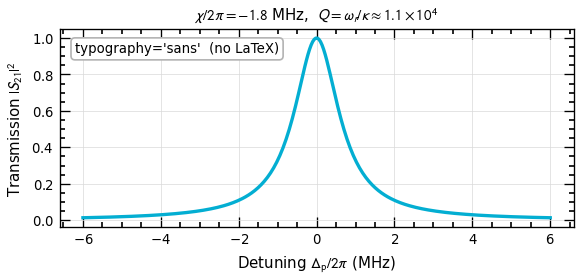

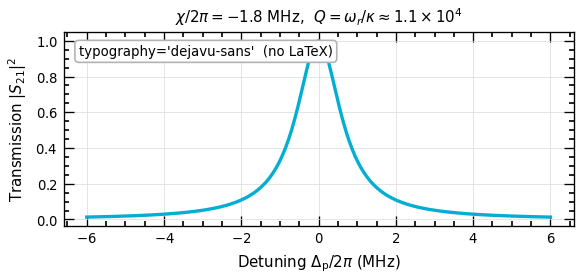

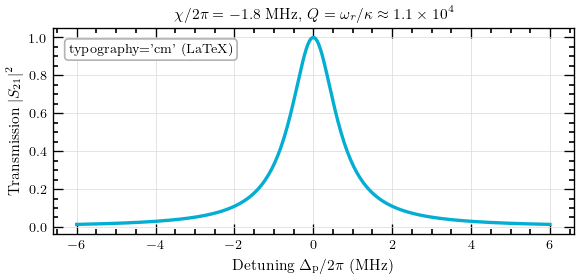

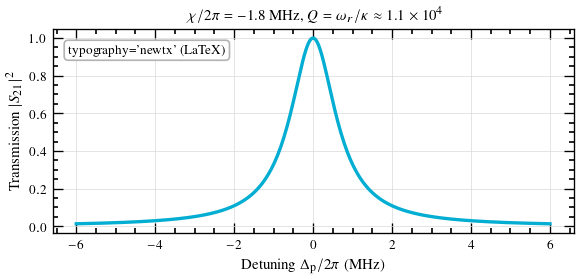

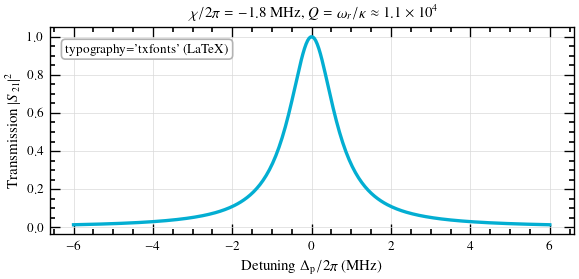

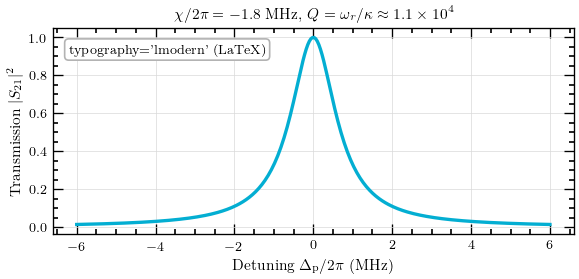

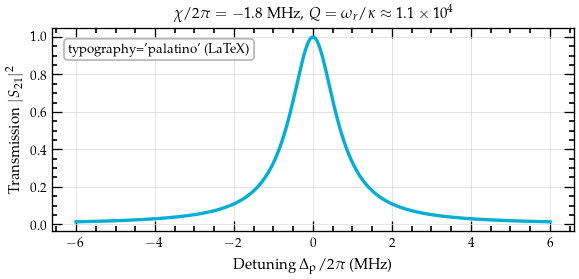

In [15]:
def demo_fig(label):
    d = np.linspace(-6, 6, 300)
    fig, ax = plt.subplots(figsize=ts.figsize(1.5, ratio=0.5))
    ax.plot(d, 1 / (1 + (2 * d / 1.4) ** 2), lw=2)
    ax.set_xlabel(r"Detuning $\Delta_\mathrm{p}/2\pi$ (MHz)")
    ax.set_ylabel(r"Transmission $|S_{21}|^{2}$")
    ax.set_title(r"$\chi/2\pi = -1.8$ MHz,  $Q = \omega_r/\kappa \approx 1.1\times10^{4}$")
    ax.text(0.03, 0.88, label, transform=ax.transAxes, fontsize=8,
            bbox=dict(boxstyle="round", fc="white", ec="0.7"))
    ts.finalize(ax)
    fig.tight_layout()
    return fig

for opt in ["scienceplots", "stix", "dejavu-serif", "sans", "dejavu-sans"]:
    ts.use(typography=opt)
    demo_fig(f"typography={opt!r}  (no LaTeX)")
    plt.show()

for opt in ["cm", "newtx", "txfonts", "lmodern", "palatino"]:
    try:
        ts.use(typography=opt)
        demo_fig(f"typography={opt!r}  (LaTeX)")
        plt.show()
    except Exception as e:
        print(f"{opt!r}: not rendered ({type(e).__name__}) -- no/incomplete TeX install")

ts.use()   # restore the notebook default